# Mini Project 2.3 — Comparing WPAN, WLAN and WMAN Technologies on Range, Throughput and Power

**Course:** Mobile Communications — Unit 2 Lab
**Tools:** Python 3, pandas (dataset), Matplotlib (trade-off charts).

**Objective.** Turn Unit 2's qualitative comparison of Bluetooth, Wi-Fi and WiMAX into a small sourced dataset, visualise the
range-versus-throughput-versus-power trade-off, and use the tool to make justified technology recommendations for three concrete deployment scenarios.

The notebook follows the manual's **Suggested Approach** steps 1–7. The final section is the written recommendation report.

## Step 1 — research: published specifications, sources and caveats

| # | Source | Used for |
|---|---|---|
| S1 | MathWorks, *Comparison of Bluetooth BR/EDR and Bluetooth LE* — https://www.mathworks.com/help/bluetooth/gs/comparison-of-bluetooth-bredr-and-bluetooth-le.html | BR/EDR rates 1/2/3 Mb/s; LE 1M, 2M, Coded 500k/125k; power classes (Class 1 = 20 dBm, Class 2 = 4 dBm, Class 3 = 0 dBm) |
| S2 | Ezurio (Laird), *What Bluetooth class?* — https://www.ezurio.com/support/faqs/what-bluetooth-class | Typical range per class: Class 1 ≈ 100 m, Class 2 ≈ 10 m, Class 3 ≈ 1 m |
| S3 | Bluetooth SIG, *Understanding Bluetooth range* — https://www.bluetooth.com/learn-about-bluetooth/key-attributes/range/ | Range spans < 1 m to > 1 km depending on PHY and design; TX power −20 to +20 dBm |
| S4 | Texas Instruments SimpleLink Academy, *BLE 5 PHY – 1M, 2M and Coded* — https://dev.ti.com/tirex/content/simplelink_academy_for_cc23xx_8_10_02_01/_build_simplelink_academy_for_cc23xx_8_10_02_01/source/cc2340rx_05_ble_5_phy.html | Relative range: 2M ≈ 0.8×, Coded S=2 ≈ 2×, Coded S=8 ≈ 4× the 1M PHY |
| S5 | TechTarget, *802.11ax vs 802.11ac* — https://www.techtarget.com/searchnetworking/tip/Whats-the-difference-between-80211ax-vs-80211ac | Peak PHY rate 6.9 Gb/s (ac) and 9.6 Gb/s (ax); bands; 256-QAM vs 1024-QAM |
| S6 | SpeedGuide, *Wireless range of 802.11* — https://speedguide.net/faq_in_q.php?qid=330 | Rule of thumb: 2.4 GHz ≈ 46 m indoor / 92 m outdoor; 5 GHz roughly one third of that indoors |
| S7 | SpeedTestHQ, *Wi-Fi power output* — https://speedtesthq.com/guides/wifi/wifi-power-output-mw-dbm | AP 17–24 dBm; phones/laptops 15–20 dBm; 20 dBm common regulatory limit |
| S8 | McGill ECE lecture notes, *WiMAX* — https://www.info413.ece.mcgill.ca/lecture%20note/E4%20WiMAX.pdf | 802.16a/d: 75 Mb/s in 20 MHz, 7–10 km typical cell, 50 km max; 802.16e: 63 Mb/s DL peak per sector in 10 MHz, 2–5 km cell |
| S9 | EE Times, *How much transmit power do WiMAX nets need?* — https://www.eetimes.com/how-much-transmit-power-do-wimax-nets-need/ | BS ≈ +43 dBm (20 W), mobile ≈ +23 dBm; ~1 km coverage per mobile BS (urban) |
| S10 | F. Rayal, *Fundamentals of WiMAX* — https://frankrayal.com/wp-content/uploads/2017/02/Fundamentals-of-WiMAX-A-Technology-Primer.pdf | 802.16e MAC throughput ≈ 14.4 Mb/s DL per 10 MHz sector; example cell radius ≈ 1.4 km at 2.5 GHz with in-building loss |
| S11 | RF Wireless World, *IEEE 802.16 WiMAX standards* — https://www.rfwireless-world.com/articles/understanding-ieee-802-16-wimax-standards | 802.16e: 3–5 km mobile / 10 km fixed; 802.16m: up to 1 Gb/s stationary, 100 Mb/s mobile, up to 10 km |
| C | Computed from the IEEE 802.11 MCS tables | 802.11ac 2×2, 80 MHz, MCS9, short GI = 866.7 Mb/s; 802.11ax 2×2, 80 MHz, MCS11 = 1201 Mb/s (typical modern client) |

**Caveats and assumptions recorded for the dataset**
* **Range depends heavily on environment, antenna and power.** "Typical" range means a usable link in the technology's normal deployment: indoors for WPAN/WLAN,
  urban/suburban outdoor for WMAN. Each entry also has a min–max band. Where a source gave only relative numbers (S4) or a very wide span (S3), the absolute typical value
  is an assumption and is marked `assumed` in the dataset.
* **Data rate.** "Peak" is the headline PHY rate of the standard. "Typical" is what one realistic device or sector gets at the PHY/MAC level. Application throughput is lower still.
  WMAN figures are **per sector, shared by every user in it**. WPAN/WLAN figures are per link.
* **Power.** Two indicators are recorded: the transmit power of the **client/end device**, which drives battery life, and of the **infrastructure end** (master/AP/base station).
  A low/medium/high class is derived from the client power.

## Step 2 — a consistent table (metres, Mbit/s, dBm)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG_DIR = "figures_2_3"; os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

data = [
    dict(tech="Bluetooth Classic (BR/EDR, Class 2)", short="BT Classic", category="WPAN", standard="IEEE 802.15.1 / BT Core",
         band_GHz="2.4", peak_Mbps=3.0, typical_Mbps=2.0, range_typ_m=10, range_min_m=1, range_max_m=100,
         client_tx_dBm=4, infra_tx_dBm=4, licensed=False, mobility="portable",
         src="S1 (rates, power), S2 (range per class)", note="typical rate = EDR pi/4-DQPSK 2 Mb/s; range band covers Class 3..1"),
    dict(tech="Bluetooth LE 5 (1M/2M PHY)", short="BLE 1M/2M", category="WPAN", standard="BT Core 5.x LE",
         band_GHz="2.4", peak_Mbps=2.0, typical_Mbps=1.0, range_typ_m=30, range_min_m=10, range_max_m=100,
         client_tx_dBm=0, infra_tx_dBm=0, licensed=False, mobility="portable",
         src="S1 (rates, power), S3 (range span); typical range assumed", note="0 dBm = most common LE setting"),
    dict(tech="Bluetooth LE 5 (Coded PHY, S=8)", short="BLE Coded", category="WPAN", standard="BT Core 5.x LE",
         band_GHz="2.4", peak_Mbps=0.125, typical_Mbps=0.125, range_typ_m=120, range_min_m=40, range_max_m=1000,
         client_tx_dBm=0, infra_tx_dBm=0, licensed=False, mobility="portable",
         src="S1 (rate), S4 (4x range of 1M), S3 (>1 km max)", note="typical range = 4 x BLE 1M typical"),
    dict(tech="Wi-Fi 5 (802.11ac)", short="Wi-Fi 5", category="WLAN", standard="IEEE 802.11ac",
         band_GHz="5", peak_Mbps=6933, typical_Mbps=867, range_typ_m=30, range_min_m=15, range_max_m=46,
         client_tx_dBm=17, infra_tx_dBm=20, licensed=False, mobility="nomadic",
         src="S5 (peak), C (typical), S6 (range), S7 (power); typical range assumed",
         note="typical = 2x2, 80 MHz, MCS9 client"),
    dict(tech="Wi-Fi 6 (802.11ax)", short="Wi-Fi 6", category="WLAN", standard="IEEE 802.11ax",
         band_GHz="2.4/5", peak_Mbps=9608, typical_Mbps=1201, range_typ_m=30, range_min_m=15, range_max_m=46,
         client_tx_dBm=17, infra_tx_dBm=20, licensed=False, mobility="nomadic",
         src="S5 (peak), C (typical), S6 (range), S7 (power); typical range assumed",
         note="typical = 2x2, 80 MHz, MCS11 client; OFDMA multi-user"),
    dict(tech="Fixed WiMAX (802.16d/2004)", short="WiMAX 16d", category="WMAN", standard="IEEE 802.16-2004",
         band_GHz="2-11 (3.5 typ.)", peak_Mbps=75, typical_Mbps=40, range_typ_m=7000, range_min_m=2000, range_max_m=50000,
         client_tx_dBm=23, infra_tx_dBm=43, licensed=True, mobility="fixed",
         src="S8 (rate, range), S9 (power); typical rate assumed ~half of peak",
         note="per sector, shared; LOS rooftop CPE for long ranges"),
    dict(tech="Mobile WiMAX (802.16e)", short="WiMAX 16e", category="WMAN", standard="IEEE 802.16e-2005",
         band_GHz="2.3/2.5/3.5", peak_Mbps=63, typical_Mbps=14.4, range_typ_m=2000, range_min_m=1000, range_max_m=10000,
         client_tx_dBm=23, infra_tx_dBm=43, licensed=True, mobility="mobile (vehicular)",
         src="S8 (peak, cell 2-5 km), S10 (typical MAC rate, ~1.4 km), S9 (power, ~1 km), S11 (10 km fixed)",
         note="10 MHz sector, shared by all users"),
    dict(tech="WiMAX 2 (802.16m)", short="WiMAX 16m", category="WMAN", standard="IEEE 802.16m",
         band_GHz="2-6", peak_Mbps=1000, typical_Mbps=100, range_typ_m=3000, range_min_m=1000, range_max_m=10000,
         client_tx_dBm=23, infra_tx_dBm=43, licensed=True, mobility="mobile (vehicular)",
         src="S11 (rate, range); power assumed as 16e; typical range assumed",
         note="1 Gb/s stationary / 100 Mb/s mobile; little commercial deployment"),
]
df = pd.DataFrame(data)
df["client_tx_mW"] = 10**(df.client_tx_dBm/10)
df["infra_tx_mW"] = 10**(df.infra_tx_dBm/10)
df["power_class"] = pd.cut(df.client_tx_dBm, bins=[-99, 5, 20, 99], labels=["low", "medium", "high"])
df[["tech", "category", "band_GHz", "peak_Mbps", "typical_Mbps", "range_min_m", "range_typ_m", "range_max_m",
    "client_tx_dBm", "infra_tx_dBm", "power_class", "licensed"]]

,tech,category,band_GHz,peak_Mbps,typical_Mbps,range_min_m,range_typ_m,range_max_m,client_tx_dBm,infra_tx_dBm,power_class,licensed
0,"Bluetooth Classic (BR/EDR, Class 2)",WPAN,2.4,3.000,2.000,1,10,100,4,4,low,False
1,Bluetooth LE 5 (1M/2M PHY),WPAN,2.4,2.000,1.000,10,30,100,0,0,low,False
2,"Bluetooth LE 5 (Coded PHY, S=8)",WPAN,2.4,0.125,0.125,40,120,1000,0,0,low,False
3,Wi-Fi 5 (802.11ac),WLAN,5,6933.000,867.000,15,30,46,17,20,medium,False
4,Wi-Fi 6 (802.11ax),WLAN,2.4/5,9608.000,1201.000,15,30,46,17,20,medium,False
5,Fixed WiMAX (802.16d/2004),WMAN,2-11 (3.5 typ.),75.000,40.000,2000,7000,50000,23,43,high,True
6,Mobile WiMAX (802.16e),WMAN,2.3/2.5/3.5,63.000,14.400,1000,2000,10000,23,43,high,True
7,WiMAX 2 (802.16m),WMAN,2-6,1000.000,100.000,1000,3000,10000,23,43,high,True


In [2]:
df[["short", "src", "note"]].style.hide(axis="index")

short,src,note
BT Classic,"S1 (rates, power), S2 (range per class)",typical rate = EDR pi/4-DQPSK 2 Mb/s; range band covers Class 3..1
BLE 1M/2M,"S1 (rates, power), S3 (range span); typical range assumed",0 dBm = most common LE setting
BLE Coded,"S1 (rate), S4 (4x range of 1M), S3 (>1 km max)",typical range = 4 x BLE 1M typical
Wi-Fi 5,"S5 (peak), C (typical), S6 (range), S7 (power); typical range assumed","typical = 2x2, 80 MHz, MCS9 client"
Wi-Fi 6,"S5 (peak), C (typical), S6 (range), S7 (power); typical range assumed","typical = 2x2, 80 MHz, MCS11 client; OFDMA multi-user"
WiMAX 16d,"S8 (rate, range), S9 (power); typical rate assumed ~half of peak","per sector, shared; LOS rooftop CPE for long ranges"
WiMAX 16e,"S8 (peak, cell 2-5 km), S10 (typical MAC rate, ~1.4 km), S9 (power, ~1 km), S11 (10 km fixed)","10 MHz sector, shared by all users"
WiMAX 16m,"S11 (rate, range); power assumed as 16e; typical range assumed",1 Gb/s stationary / 100 Mb/s mobile; little commercial deployment


## Step 3 — derived quantities (figures of merit)
* **throughput per metre of range** = typical Mb/s ÷ typical range (m), as suggested in the manual. A high value means fast but short.
* **range × throughput** (Mb/s·km), the classic "rate-distance product", where a high value means a link is both fast and long.
* **coverage area per access point/base station**, π r² at typical range.
* **transmit-energy efficiency** = typical Mb/s ÷ client TX power (mW), a crude proxy for bits per joule spent on transmission at the battery-powered end
  (receiver and processing power are ignored). Note that this metric rewards *fast* radios. It suits bulk transfers but not
  small-packet sensors, whose energy is dominated by wake-up and connection overhead (see Scenario A).

In [3]:
df["Mbps_per_m"] = df.typical_Mbps / df.range_typ_m
df["Mbps_x_km"] = df.typical_Mbps * df.range_typ_m/1000
df["coverage_km2"] = np.pi*(df.range_typ_m/1000)**2
df["Mbps_per_mW"] = df.typical_Mbps / df.client_tx_mW
derived = df[["short", "category", "typical_Mbps", "range_typ_m", "Mbps_per_m", "Mbps_x_km", "coverage_km2", "Mbps_per_mW", "power_class"]]
derived.style.format({"typical_Mbps": "{:.3g}", "range_typ_m": "{:,.0f}", "Mbps_per_m": "{:.3g}", "Mbps_x_km": "{:.3g}",
                      "coverage_km2": "{:.3g}", "Mbps_per_mW": "{:.3g}"}).hide(axis="index")

short,category,typical_Mbps,range_typ_m,Mbps_per_m,Mbps_x_km,coverage_km2,Mbps_per_mW,power_class
BT Classic,WPAN,2,10,0.2,0.02,0.000314,0.796,low
BLE 1M/2M,WPAN,1,30,0.0333,0.03,0.00283,1,low
BLE Coded,WPAN,0.125,120,0.00104,0.015,0.0452,0.125,low
Wi-Fi 5,WLAN,867,30,28.9,26,0.00283,17.3,medium
Wi-Fi 6,WLAN,1.2e+03,30,40,36,0.00283,24,medium
WiMAX 16d,WMAN,40,"7,000",0.00571,280,154,0.2,high
WiMAX 16e,WMAN,14.4,"2,000",0.0072,28.8,12.6,0.0722,high
WiMAX 16m,WMAN,100,"3,000",0.0333,300,28.3,0.501,high


In [4]:
for col, label in [("Mbps_per_m", "throughput per metre (Mb/s per m)"), ("Mbps_x_km", "rate x range (Mb/s.km)"),
                   ("coverage_km2", "coverage per AP/BS (km2)"), ("Mbps_per_mW", "Mb/s per mW of client TX power")]:
    top = df.sort_values(col, ascending=False).iloc[0]
    print(f"Highest {label:<34}: {top['short']:<10} ({top[col]:.3g})")
print()
print(f"Wi-Fi 6 vs WiMAX 16e: {df.loc[4,'typical_Mbps']/df.loc[6,'typical_Mbps']:.0f}x the rate, "
      f"{df.loc[6,'range_typ_m']/df.loc[4,'range_typ_m']:.0f}x shorter range, "
      f"{df.loc[6,'coverage_km2']/df.loc[4,'coverage_km2']:.0f}x smaller area per AP")
print(f"BLE vs Wi-Fi client TX power: {df.loc[3,'client_tx_mW']/df.loc[1,'client_tx_mW']:.0f}x less radiated power for BLE")

Highest throughput per metre (Mb/s per m) : Wi-Fi 6    (40)
Highest rate x range (Mb/s.km)            : WiMAX 16m  (300)
Highest coverage per AP/BS (km2)          : WiMAX 16d  (154)
Highest Mb/s per mW of client TX power    : Wi-Fi 6    (24)

Wi-Fi 6 vs WiMAX 16e: 83x the rate, 67x shorter range, 4444x smaller area per AP
BLE vs Wi-Fi client TX power: 50x less radiated power for BLE


## Step 4 — trade-off visualization
The main chart is a **log–log scatter** of typical range against typical throughput. The values span five orders of magnitude, so linear axes would squash every WPAN point into a corner.
* Marker **size** is client transmit power and the dBm value is printed next to each point. Marker **colour** is the network class.
* The horizontal bars show the min–max range band, and the vertical line runs from the typical rate up to the standard's peak rate.
* The dotted diagonals are lines of constant rate × range. Points further up and right are both faster and longer-reaching, at a cost the marker size shows.

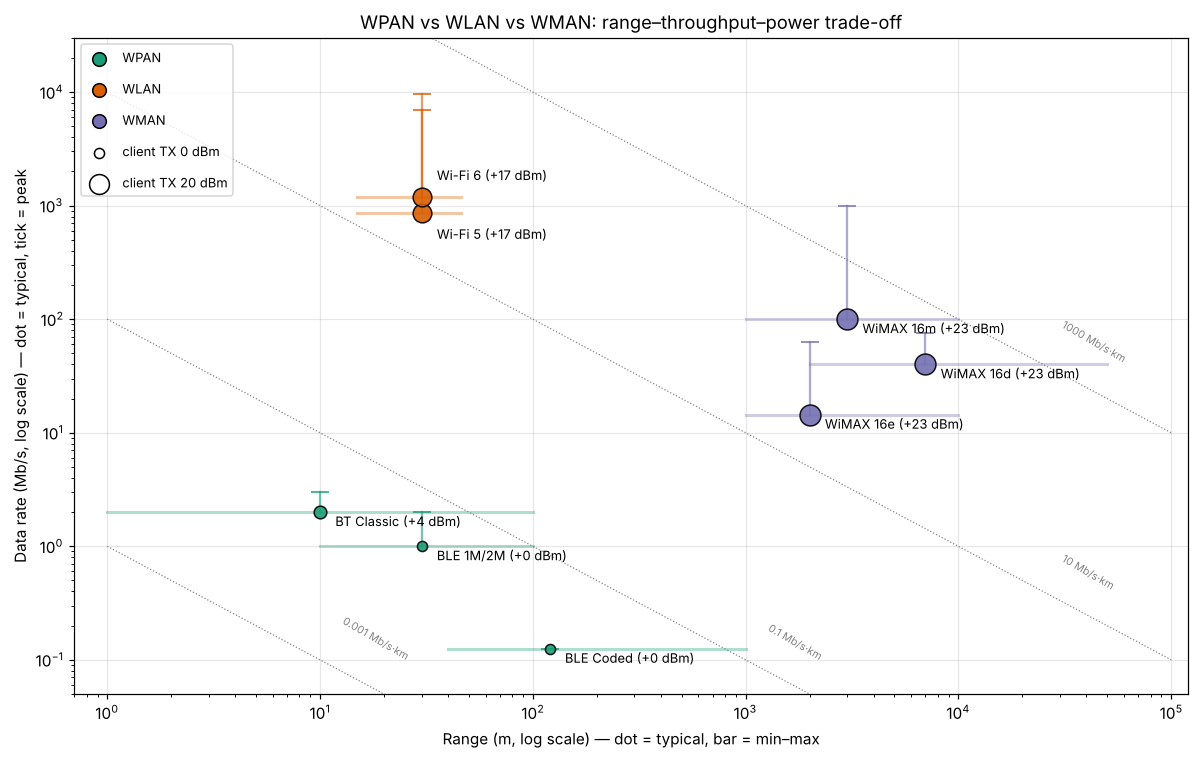

In [5]:
COL = {"WPAN": "#1b9e77", "WLAN": "#d95f02", "WMAN": "#7570b3"}
def msize(dbm):                       # marker area grows with client TX power
    return 25*(1 + (dbm + 3)/4)
OFFSET = {"Wi-Fi 5": (10, -14), "Wi-Fi 6": (10, 14)}   # keep overlapping labels apart
fig, ax = plt.subplots(figsize=(11, 7))
for prod in [1e-3, 1e-1, 1e1, 1e3]:                       # iso rate x range lines (Mb/s.km)
    r = np.logspace(0, 5, 50); ax.plot(r, prod/(r/1000), ":", color="gray", lw=0.8)
    xl = 3e4 if prod/30 > 0.08 else 1000*prod/0.08
    ax.text(xl, prod/(xl/1000)*1.25, f"{prod:g} Mb/s·km", color="gray", fontsize=7, rotation=-30)
for _, r in df.iterrows():
    c = COL[r.category]
    ax.plot([r.range_min_m, r.range_max_m], [r.typical_Mbps]*2, color=c, lw=2, alpha=0.35)
    ax.plot([r.range_typ_m]*2, [r.typical_Mbps, r.peak_Mbps], color=c, lw=1.5, alpha=0.6)
    ax.plot(r.range_typ_m, r.peak_Mbps, marker="_", ms=12, color=c)
    ax.scatter(r.range_typ_m, r.typical_Mbps, s=msize(r.client_tx_dBm), color=c, edgecolor="k", zorder=3, alpha=0.9)
    ax.annotate(f"{r.short} ({r.client_tx_dBm:+d} dBm)", (r.range_typ_m, r.typical_Mbps), xytext=OFFSET.get(r.short, (10, -6)),
                textcoords="offset points", fontsize=8.5, va="center")
for cat, c in COL.items():
    ax.scatter([], [], color=c, s=80, label=cat, edgecolor="k")
for dbm in [0, 20]:
    ax.scatter([], [], s=msize(dbm), color="white", edgecolor="k", label=f"client TX {dbm} dBm")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(0.7, 1.2e5); ax.set_ylim(0.05, 3e4)
ax.set_xlabel("Range (m, log scale) — dot = typical, bar = min–max")
ax.set_ylabel("Data rate (Mb/s, log scale) — dot = typical, tick = peak")
ax.set_title("WPAN vs WLAN vs WMAN: range–throughput–power trade-off")
ax.legend(loc="upper left", fontsize=8.5, labelspacing=1.2)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/tradeoff_scatter.png", bbox_inches="tight"); plt.show()

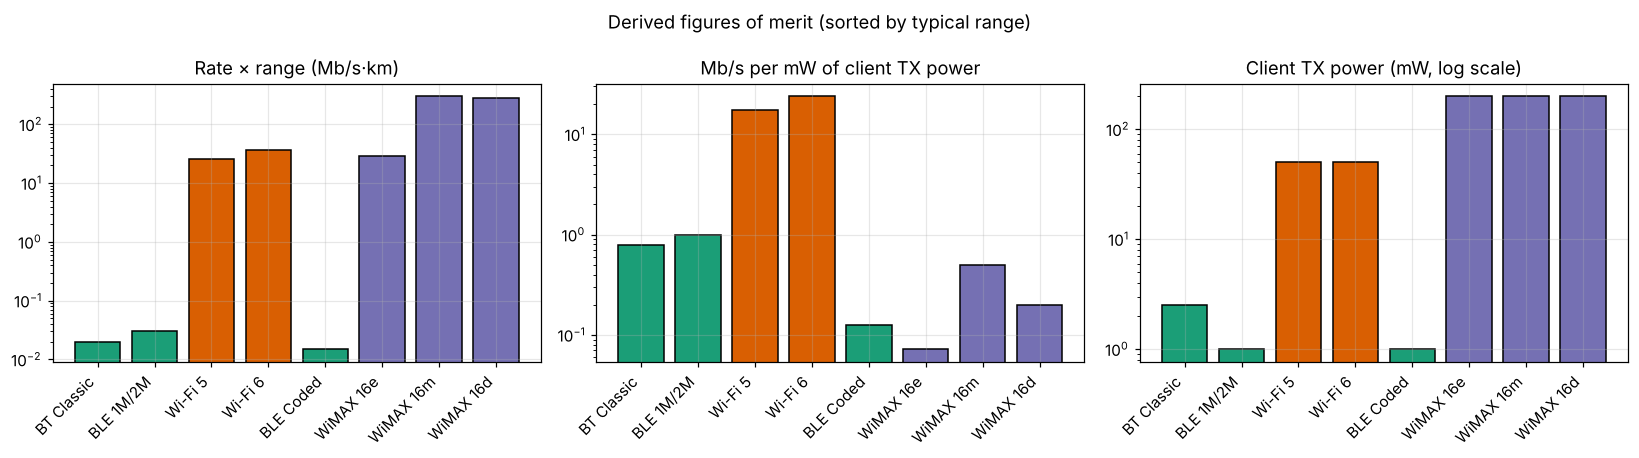

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
order = df.sort_values("range_typ_m")
cols = [COL[c] for c in order.category]
for ax, col, title, logy in [(axes[0], "Mbps_x_km", "Rate × range (Mb/s·km)", True),
                             (axes[1], "Mbps_per_mW", "Mb/s per mW of client TX power", True),
                             (axes[2], "client_tx_mW", "Client TX power (mW, log scale)", True)]:
    ax.bar(order.short, order[col], color=cols, edgecolor="k")
    if logy: ax.set_yscale("log")
    ax.set_title(title); ax.tick_params(axis="x", rotation=45)
    for lbl in ax.get_xticklabels(): lbl.set_ha("right")
fig.suptitle("Derived figures of merit (sorted by typical range)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/derived_metrics.png", bbox_inches="tight"); plt.show()

## Step 5 — deployment scenarios with explicit, numbered requirements

**Scenario A — smart home with many low-power sensors**
1. Coverage: one house plus garden, longest path ≈ 20 m through 2–3 interior walls.
2. Devices: ≈ 40 battery sensors (door/window, temperature, motion, leak) plus a hub, with phone access.
3. Throughput: < 1 kb/s average per sensor (small reports every few seconds to minutes); the hub needs < 0.1 Mb/s aggregate.
4. Power: coin-cell or AA battery, ≥ 2 years of life, so the radio must transmit at ≤ ~4 dBm and sleep most of the time.

**Scenario B — university campus network**
1. Coverage: ≈ 500 m × 400 m campus, 12 buildings (lecture halls, library, offices), indoor plus courtyards.
2. Devices: ≈ 4,000 simultaneous laptops/phones, up to 300 in one lecture hall.
3. Throughput: ≥ 20 Mb/s per active user (video lectures, cloud tools), so several Gb/s aggregate.
4. Power: access points are mains/PoE powered; clients are laptops/phones with rechargeable batteries (moderate TX power is acceptable).

**Scenario C — metro-area fixed wireless link**
1. Coverage: link a branch site (e.g. a district clinic or school) to the main office **6 km** away across town; rooftop antennas at both ends.
2. Devices: one fixed customer-premises unit (CPE) serving a LAN of ~50 users.
3. Throughput: ≥ 20 Mb/s downlink, ≥ 5 Mb/s uplink, sustained.
4. Power: mains power at both ends with no battery constraint; high TX power is acceptable.

In [7]:
scenarios = {
    "A: smart home":  dict(range_m=20,   min_Mbps=0.1, max_client_dBm=4,  color="#1b9e77"),
    "B: campus":      dict(range_m=30,   min_Mbps=20,  max_client_dBm=20, color="#d95f02"),   # per-AP cell radius
    "C: metro link":  dict(range_m=6000, min_Mbps=20,  max_client_dBm=99, color="#7570b3"),
}

def evaluate(req):
    ok = df[(df.range_max_m >= req["range_m"]) & (df.typical_Mbps >= req["min_Mbps"]) &
            (df.client_tx_dBm <= req["max_client_dBm"])].copy()
    # margins relative to the requirement (in dB-like log10 ratios)
    ok["range_margin_x"] = ok.range_typ_m / req["range_m"]
    ok["rate_margin_x"] = ok.typical_Mbps / req["min_Mbps"]
    return ok[["short", "category", "typical_Mbps", "range_typ_m", "range_max_m", "client_tx_dBm",
               "range_margin_x", "rate_margin_x", "licensed"]]

for name, req in scenarios.items():
    print(f"\n=== Scenario {name}: range >= {req['range_m']} m, rate >= {req['min_Mbps']} Mb/s, "
          f"client TX <= {req['max_client_dBm'] if req['max_client_dBm'] < 99 else 'any'} dBm")
    print(evaluate(req).to_string(index=False, float_format=lambda v: f"{v:.3g}"))


=== Scenario A: smart home: range >= 20 m, rate >= 0.1 Mb/s, client TX <= 4 dBm
     short category  typical_Mbps  range_typ_m  range_max_m  client_tx_dBm  range_margin_x  rate_margin_x  licensed
BT Classic     WPAN             2           10          100              4             0.5             20     False
 BLE 1M/2M     WPAN             1           30          100              0             1.5             10     False
 BLE Coded     WPAN         0.125          120         1000              0               6           1.25     False

=== Scenario B: campus: range >= 30 m, rate >= 20 Mb/s, client TX <= 20 dBm
  short category  typical_Mbps  range_typ_m  range_max_m  client_tx_dBm  range_margin_x  rate_margin_x  licensed
Wi-Fi 5     WLAN           867           30           46             17               1           43.4     False
Wi-Fi 6     WLAN       1.2e+03           30           46             17               1             60     False

=== Scenario C: metro link: range >= 6

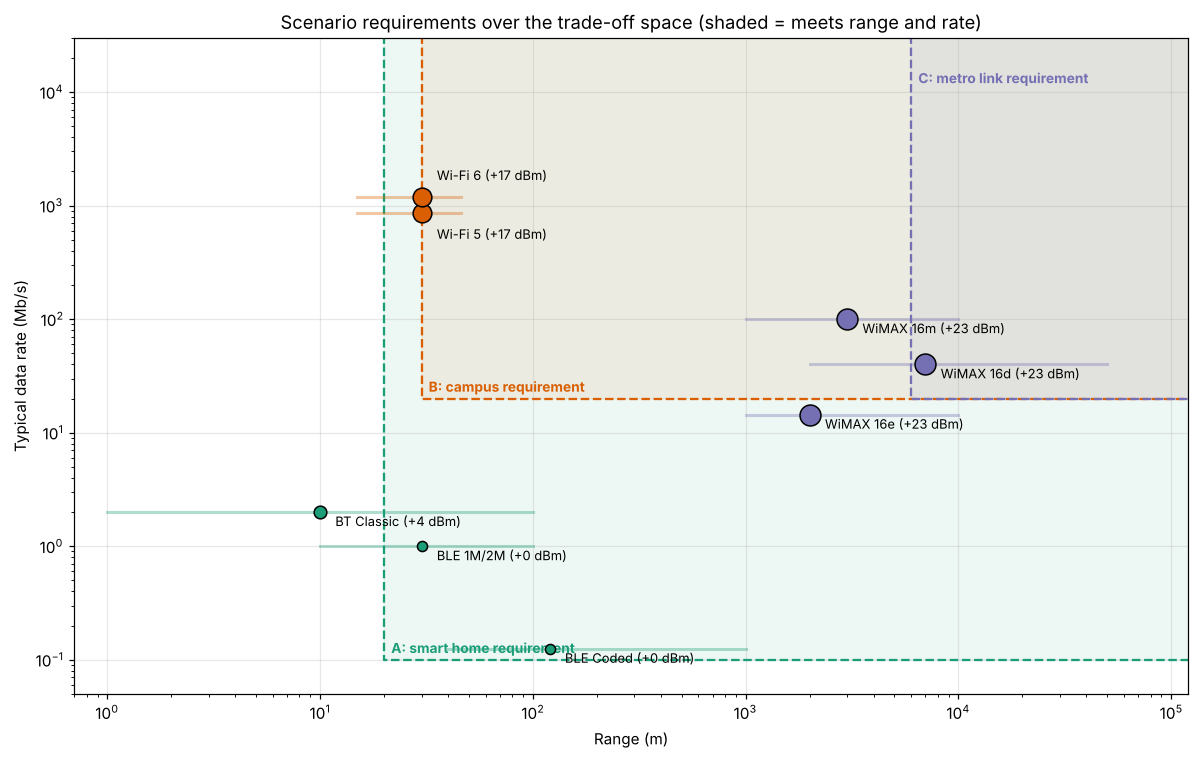

In [8]:
# Same scatter with each scenario's requirement region shaded (feasible = right of and above the corner)
fig, ax = plt.subplots(figsize=(11, 7))
for name, req in scenarios.items():
    ax.add_patch(plt.Rectangle((req["range_m"], req["min_Mbps"]), 1e6, 1e6, color=req["color"], alpha=0.08))
    ax.plot([req["range_m"], req["range_m"], 2e5], [3e5, req["min_Mbps"], req["min_Mbps"]], color=req["color"], lw=1.5, ls="--")
    ty = 1.2e4 if name.startswith("C") else req["min_Mbps"]*1.15
    ax.text(req["range_m"]*1.08, ty, f"{name} requirement", color=req["color"], fontsize=9, fontweight="bold")
for _, r in df.iterrows():
    c = COL[r.category]
    ax.plot([r.range_min_m, r.range_max_m], [r.typical_Mbps]*2, color=c, lw=2, alpha=0.35)
    ax.scatter(r.range_typ_m, r.typical_Mbps, s=msize(r.client_tx_dBm), color=c, edgecolor="k", zorder=3)
    ax.annotate(f"{r.short} ({r.client_tx_dBm:+d} dBm)", (r.range_typ_m, r.typical_Mbps), xytext=OFFSET.get(r.short, (10, -6)),
                textcoords="offset points", fontsize=8.5, va="center")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.7, 1.2e5); ax.set_ylim(0.05, 3e4)
ax.set_xlabel("Range (m)"); ax.set_ylabel("Typical data rate (Mb/s)")
ax.set_title("Scenario requirements over the trade-off space (shaded = meets range and rate)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/scenarios_overlay.png", bbox_inches="tight"); plt.show()

## Step 6 — capacity sanity checks used in the justifications

In [9]:
# Scenario A: is BLE's 1 Mb/s enough for 40 sensors? Airtime used.
n_sensors, bytes_per_report, period_s = 40, 30, 10
load_bps = n_sensors*bytes_per_report*8/period_s
print(f"A: 40 sensors x 30 B every 10 s = {load_bps:.0f} b/s = {100*load_bps/1e6:.3f} % of BLE 1M airtime")
# battery: rough average current with 0 dBm BLE radio active ~5 mA for ~1 ms per report (typical SoC values, assumption)
i_active_mA, t_active_ms, i_sleep_uA, cap_mAh = 5.0, 1.0, 2.0, 220   # CR2032
i_avg_uA = i_active_mA*1000*(t_active_ms/1000)/period_s + i_sleep_uA
print(f"   coin-cell estimate (assumed SoC currents): avg {i_avg_uA:.1f} uA -> ~{cap_mAh*1000/i_avg_uA/24/365:.1f} years on a CR2032")

# Scenario B: Wi-Fi 6 APs needed for coverage and for capacity
area_m2, floors_factor = 500*400, 1.0
r_ap = 30; cell_area = np.pi*r_ap**2*0.6          # 60 % to allow overlap / walls
ap_cov = int(np.ceil(area_m2*floors_factor/cell_area))
users, per_user, ap_eff_Mbps = 4000, 20, 400       # realistic aggregate per AP (MAC efficiency + sharing), assumption
ap_cap = int(np.ceil(users*per_user/ap_eff_Mbps))
print(f"B: coverage needs ~{ap_cov} APs; capacity needs ~{ap_cap} APs -> plan ~{max(ap_cov, ap_cap)} Wi-Fi 6 APs "
      f"(capacity-limited); a 300-seat hall needs ~{int(np.ceil(300*per_user/ap_eff_Mbps))} APs")
wimax_bs = int(np.ceil(users*per_user/(3*df.loc[6, 'typical_Mbps'])))
print(f"   for comparison, 4000 x 20 Mb/s over 3-sector 802.16e sites would need ~{wimax_bs} base-station sites")

# Scenario C: free-space + log-distance link budget at 3.5 GHz, 6 km, rooftop LOS
f, d = 3500, 6.0
fspl = 20*np.log10(d) + 20*np.log10(f) + 32.44
eirp, g_rx, sens = 43 + 17, 17, -85        # BS 43 dBm + 17 dBi sector; CPE 17 dBi panel; sensitivity for 16-QAM (assumed)
prx = eirp + g_rx - fspl
print(f"C: FSPL(6 km, 3.5 GHz) = {fspl:.1f} dB -> P_RX = {prx:.1f} dBm vs ~{sens} dBm sensitivity -> "
      f"{prx - sens:.0f} dB margin for shadowing/rain/obstruction (LOS rooftop)")

A: 40 sensors x 30 B every 10 s = 960 b/s = 0.096 % of BLE 1M airtime
   coin-cell estimate (assumed SoC currents): avg 2.5 uA -> ~10.0 years on a CR2032
B: coverage needs ~118 APs; capacity needs ~200 APs -> plan ~200 Wi-Fi 6 APs (capacity-limited); a 300-seat hall needs ~15 APs
   for comparison, 4000 x 20 Mb/s over 3-sector 802.16e sites would need ~1852 base-station sites
C: FSPL(6 km, 3.5 GHz) = 118.9 dB -> P_RX = -41.9 dBm vs ~-85 dBm sensitivity -> 43 dB margin for shadowing/rain/obstruction (LOS rooftop)


## Step 7 — recommendation report

### Comparison summary
The table and chart above show the Unit 2 classification in numbers. **WPAN** (Bluetooth) works at 1–100 m and ≤ 3 Mb/s with client power of ≤ 4 dBm (≤ 2.5 mW).
**WLAN** (Wi-Fi 5/6) works at 15–46 m indoors and roughly 0.9–1.2 Gb/s per typical client (6.9–9.6 Gb/s peak) at 17–20 dBm.
**WMAN** (WiMAX) works at 1–10 km (up to 50 km for fixed line-of-sight links) and tens of Mb/s per *shared* sector, with 43 dBm base stations and 23 dBm terminals.
No technology wins on all three axes. Each class sits on a different part of the trade-off: range is bought with transmit power, licensed spectrum and shared capacity,
and throughput is bought with short cells and higher power.

### Scenario A — smart home → **Bluetooth Low Energy 5** (1M PHY, Coded PHY for the garden)
* **Numbers:** the requirement is ≥ 20 m, ≥ 0.1 Mb/s, ≤ 4 dBm. BLE 1M gives ~30 m typical at **0 dBm (1 mW)** and 1 Mb/s, which is 10× the needed rate.
  The 40 sensors use only ≈ 0.1 % of the airtime. For the far corner of the garden, the Coded PHY extends range about 4× (≈ 120 m) at 125 kb/s with no extra power.
* **Battery check:** with assumed typical radio currents (5 mA for 1 ms per report, 2 µA sleep), the average current is ≈ 2.5 µA. That is a theoretical ~10 years on a CR2032,
  so in practice the cell's shelf life limits it, comfortably above the 2-year requirement.
* **Why not the others:** Wi-Fi meets range and rate but its clients transmit at ~17 dBm (≈ 50× BLE's power). The derived "Mb/s per mW" metric actually favours Wi-Fi for
  *bulk* transfers, because it moves bits much faster. A sensor, however, sends a few bytes and then sleeps, so its battery life is set by the fixed cost of waking up,
  re-associating and keeping the link alive, which is far lower for BLE. With Wi-Fi, coin-cell sensors would last weeks or months rather than years.
  Bluetooth Classic is connection-oriented, limited to 7 active slaves per piconet, and uses more energy than LE. WiMAX would mean licensed spectrum and 23 dBm terminals for a 20 m job.
* **Secondary factors:** unlicensed 2.4 GHz with no fees; every phone supports BLE natively for setup; Bluetooth Mesh or a hub covers multi-room layouts.
  The complication is that BLE shares 2.4 GHz with Wi-Fi, but adaptive frequency hopping reduces that interference. (Zigbee/Thread on IEEE 802.15.4 are equally valid WPAN choices
  outside this dataset.)

### Scenario B — campus network → **Wi-Fi 6 (802.11ax)** with a dense AP deployment
* **Numbers:** the requirement is ≥ 20 Mb/s per user for 4,000 users, so ~80 Gb/s aggregate. Wi-Fi 6 offers ~1.2 Gb/s per typical client link (9.6 Gb/s peak) but only ~30 m per AP.
  The sizing above shows that coverage alone needs ~120 APs, while capacity needs ~200. The design is therefore **capacity-limited**, which is exactly the regime where short cells are an advantage:
  small cells re-use the spectrum many times. A 300-seat hall needs ~15 APs on non-overlapping 5 GHz channels.
* **Why not the others:** a single 802.16e sector delivers only ~14 Mb/s shared by everyone in it, so the same demand would need ~1,850 three-sector WiMAX sites, which is absurd.
  Bluetooth's ≤ 3 Mb/s and ~10 m are orders of magnitude short. Wi-Fi 6 is preferred over Wi-Fi 5 because OFDMA and BSS colouring are designed for dense halls with many simultaneous users,
  and it also runs in 2.4 GHz for older devices.
* **Secondary factors:** unlicensed spectrum, mature and cheap enterprise equipment, and universal client support. APs need PoE and wired backhaul (fibre/Ethernet) to every building.
  Mobility is limited to walking speed with roaming between APs, which is acceptable on a campus.

### Scenario C — 6 km metro fixed link → **Fixed WiMAX (802.16d)** or 802.16e in fixed mode, rooftop LOS
* **Numbers:** the requirement is 6 km and ≥ 20 Mb/s DL. Only the WMAN entries reach 6 km. Fixed 802.16d has a 7 km typical / 50 km maximum LOS range and a 75 Mb/s peak per 20 MHz sector (~40 Mb/s typical),
  which meets the 20 Mb/s target with margin. A simple link budget at 3.5 GHz (43 dBm BS, 17 dBi antennas at both ends) gives about **−42 dBm** received power,
  roughly 43 dB above a typical 16-QAM sensitivity of about −85 dBm, leaving ample room for shadowing, rain and partial obstruction.
  802.16e (≈ 14 Mb/s typical per sector) fails the 20 Mb/s filter, and would be marginal anyway since that capacity is shared with other customers.
  802.16m also passes the filter (100 Mb/s) at the edge of its range, but it has had very little commercial deployment.
* **Why not the others:** Wi-Fi's 15–46 m and Bluetooth's ≤ 100 m are far too short with standard omnidirectional antennas. (Point-to-point Wi-Fi with high-gain dish antennas *can* span kilometres,
  which is a common low-cost alternative, but it falls outside the "standard deployment" assumptions of this dataset.)
* **Secondary factors that complicate the numeric answer:** WiMAX uses **licensed** spectrum (2.3/2.5/3.5 GHz), so it requires an operator licence or service contract.
  The technology is also **no longer mature in the market**. Most operators have migrated to LTE/5G fixed-wireless access, which offers the same OFDMA/MIMO principles with better device availability,
  and new WiMAX equipment is hard to source. The engineering conclusion (WMAN-class technology, licensed sub-6 GHz, rooftop LOS, ~40 Mb/s per sector) remains valid; in practice it would be built today with
  LTE/5G FWA or a licensed point-to-point microwave link.

### Conclusion
Matching each scenario's numbers against the dataset gives one clear choice per case:
**BLE for low-power short-range sensing, Wi-Fi 6 for high-capacity local access, and WMAN-class fixed wireless for kilometre-scale links**.
That is the same WPAN/WLAN/WMAN division Unit 2 describes qualitatively. The secondary factors (licensing, ecosystem maturity, battery life) reinforce the first two choices and qualify the third.

## Deliverable and evaluation checklist

| Manual item | Where |
|---|---|
| Dataset: ≥ 3 technologies (8 entries across WPAN/WLAN/WMAN) with range (m), data rate (Mb/s), power (dBm + class), and sources noted | Steps 1–2 |
| Script loads the dataset and computes derived metrics (throughput-per-metre, etc.) | Step 3 |
| ≥ 1 chart of the three-way trade-off (log–log, size = power, colour = class) | Step 4 (+ derived metrics, scenario overlay) |
| ≥ 2, ideally 3, scenarios with numbered requirements | Step 5 (3 scenarios) |
| Justified recommendation per scenario citing numbers, plus secondary factors | Steps 6–7 |
| Report: table + chart + recommendations + sources | Step 7 (and the separate report document) |

Figures are saved in `figures_2_3/`; the dataset is also exported to `wireless_tech_dataset.csv`.

In [10]:
df.to_csv("wireless_tech_dataset.csv", index=False)
print("saved wireless_tech_dataset.csv;", sorted(os.listdir(FIG_DIR)))

saved wireless_tech_dataset.csv; ['derived_metrics.png', 'scenarios_overlay.png', 'tradeoff_scatter.png']
